In [ ]:
import torch
import torch.nn as nn

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# total data
X = np.linspace(0, np.pi*2, 40)
y = np.sin(X) + 0.3*np.random.randn(len(X))

# train / test random split
random_index = np.random.permutation(len(X))
train_size = int(len(X) * 0.7)
X_train, X_test = X[random_index[:train_size]], X[random_index[train_size:]]
y_train, y_test = y[random_index[:train_size]], y[random_index[train_size:]]

# z-score normalization constant
mean = X_train.mean()
std = X_train.std()
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

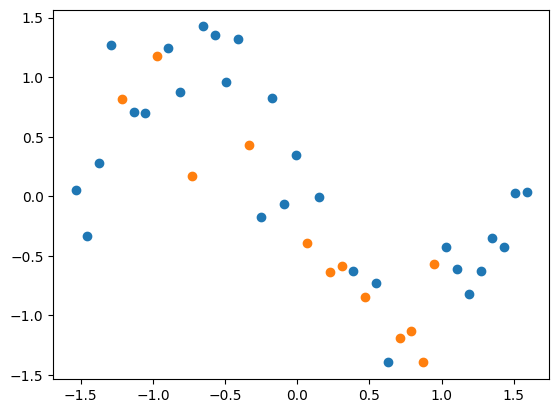

In [ ]:
plt.scatter(X_train, y_train)
plt.scatter(X_test, y_test)
plt.show()

In [ ]:
class SimpleMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Linear(1, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        return self.layers(x)


In [ ]:
model = SimpleMLP()

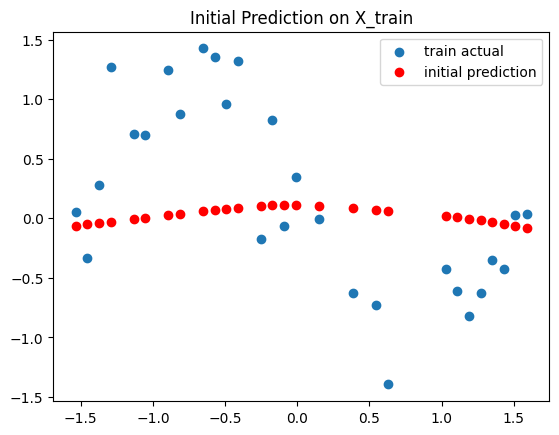

In [ ]:
with torch.no_grad():
    # X_train을 (N, 1) 형태로 텐서 변환하여 초기 모델의 예측값 계산
    y_initial_pred = model(torch.tensor(X_train, dtype=torch.float32).reshape(-1, 1)).numpy()

plt.scatter(X_train, y_train, label='train actual')
plt.scatter(X_train, y_initial_pred, label='initial prediction', color='red')
plt.legend()
plt.title("Initial Prediction on X_train")
plt.show()

In [ ]:
# learning sample data
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

train_loss = []
test_loss = []

for epoch in range(100):
    for x, t in zip(X_train, y_train):
        x = torch.tensor(x, dtype=torch.float32).reshape(1, -1)
        t = torch.tensor(t, dtype=torch.float32).reshape(1, -1)

        y = model(x)
        loss = loss_fn(y, t)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    # printing train / test loss
    with torch.no_grad():
        tr_loss = loss_fn(model(torch.tensor(X_train, dtype=torch.float32).reshape(-1, 1)), torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1))
        te_loss = loss_fn(model(torch.tensor(X_test, dtype=torch.float32).reshape(-1, 1)), torch.tensor(y_test, dtype=torch.float32).reshape(-1, 1))
        print(f"epoch: {epoch}, train loss: {round(tr_loss.item(), 2)}, test loss: {round(te_loss.item(), 2)}")
        train_loss.append(tr_loss.item())
        test_loss.append(te_loss.item())

epoch: 0, train loss: 0.51, test loss: 0.89
epoch: 1, train loss: 0.38, test loss: 0.72
epoch: 2, train loss: 0.26, test loss: 0.43
epoch: 3, train loss: 0.19, test loss: 0.42
epoch: 4, train loss: 0.14, test loss: 0.27
epoch: 5, train loss: 0.18, test loss: 0.21
epoch: 6, train loss: 0.33, test loss: 0.37
epoch: 7, train loss: 0.17, test loss: 0.19
epoch: 8, train loss: 0.12, test loss: 0.16
epoch: 9, train loss: 0.16, test loss: 0.12
epoch: 10, train loss: 0.16, test loss: 0.12
epoch: 11, train loss: 0.14, test loss: 0.12
epoch: 12, train loss: 0.13, test loss: 0.12
epoch: 13, train loss: 0.13, test loss: 0.12
epoch: 14, train loss: 0.13, test loss: 0.13
epoch: 15, train loss: 0.12, test loss: 0.11
epoch: 16, train loss: 0.12, test loss: 0.15
epoch: 17, train loss: 0.14, test loss: 0.13
epoch: 18, train loss: 0.12, test loss: 0.12
epoch: 19, train loss: 0.11, test loss: 0.12
epoch: 20, train loss: 0.11, test loss: 0.12
epoch: 21, train loss: 0.11, test loss: 0.13
epoch: 22, train los

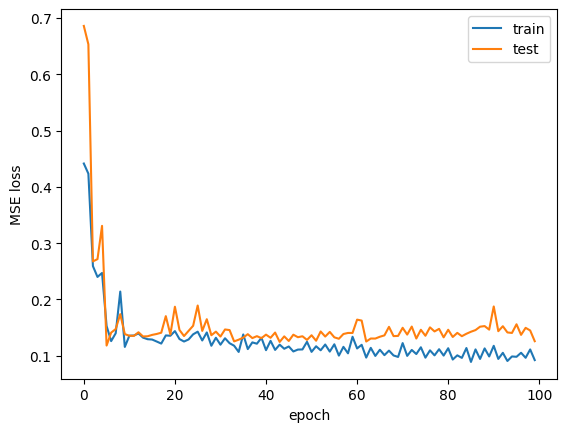

In [ ]:
plt.plot(train_loss, label='train')
plt.plot(test_loss, label='test')
plt.legend()
plt.xlabel('epoch')
plt.ylabel('MSE loss')
plt.show()

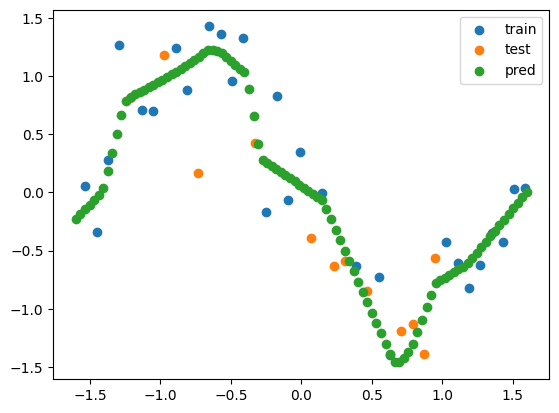

In [ ]:
hr = np.linspace(-1.6, 1.6, 100)
y_pred = model(torch.tensor(hr, dtype=torch.float32).reshape(-1, 1)).detach().numpy()
plt.scatter(X_train, y_train, label='train')
plt.scatter(X_test, y_test, label='test')
plt.scatter(hr, y_pred, label='pred')
plt.legend()
plt.show()

--- 실제 y_train 값 ---
[ 0.27796301 -0.62975031 -0.425343   -0.42941127  1.24157819 -0.3529371
 -1.39457722 -0.72369207 -0.6066316   0.70415823  0.82744593  1.42476841
  1.26632668 -0.33722171 -0.82066306  0.87892529 -0.17013925  0.03607578
  0.34440136 -0.0641537  -0.62794662  1.3562751   0.95529734  0.69666667
  0.03047732  1.3227726  -0.0043439   0.05216123]

--- 기존 모델의 X_train 예측값 ---
[ 0.18571009 -0.72597235 -0.7256313  -0.24594094  1.0333351  -0.36478317
 -1.3837918  -1.1650383  -0.666291    0.8720957   0.1956256   1.2263635
  0.58244276 -0.04472601 -0.5962023   1.0920585   0.26167527 -0.00825663
  0.0629836   0.12932277 -0.48362553  1.2025014   1.120317    0.92260325
 -0.12709881  1.0385892  -0.07163914 -0.14364587]

--- 새 모델(추가 입력 노드=-1, 랜덤 가중치)의 예측값 ---
[-0.31758052 -0.37789953 -0.56052524 -0.5398808  -0.0814542  -0.5601531
 -0.43649876 -0.41485655 -0.57840747 -0.16954158 -0.1612715  -0.04474106
 -0.2570992  -0.38700205 -0.59210664 -0.05504997 -0.13334437 -0.44675064
 -0.2263325

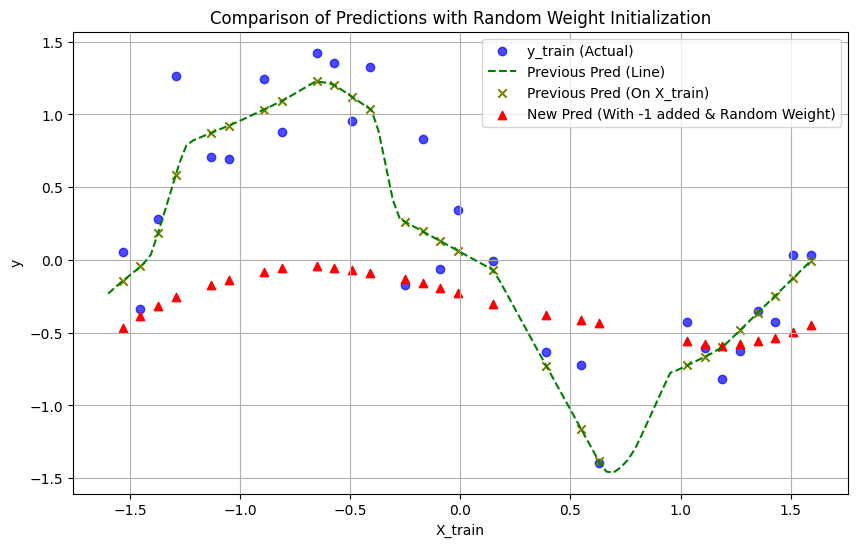

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# 1. 가중치를 보존하며 입력 노드가 2개인 새로운 MLP 정의
class ExpandedMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(2, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        return self.layers(x)

# 새로운 모델 객체 생성
expanded_model = ExpandedMLP()

# 기존 모델(model)의 가중치를 복사하여 이식
with torch.no_grad():
    # 기존 1개 입력 가중치를 첫 번째 열에 복사
    expanded_model.layers[0].weight[:, :1] = model.layers[0].weight.clone()

    # 추가된 두 번째 입력 노드의 가중치를 정규분포(Mean=0, Std=1)로 무작위 초기화
    expanded_model.layers[0].weight[:, 1:].normal_(mean=0.0, std=1.0)

    # 편향(bias) 복사
    expanded_model.layers[0].bias = nn.Parameter(model.layers[0].bias.clone())

    # 나머지 레이어 가중치는 기존 모델에서 그대로 복사
    expanded_model.layers[2].weight = nn.Parameter(model.layers[2].weight.clone())
    expanded_model.layers[2].bias = nn.Parameter(model.layers[2].bias.clone())
    expanded_model.layers[4].weight = nn.Parameter(model.layers[4].weight.clone())
    expanded_model.layers[4].bias = nn.Parameter(model.layers[4].bias.clone())

# 2. 데이터 구성
# 기존 입력 노드: X_train (N, 1)
# 추가 입력 노드: -1로 채워진 (N, 1) 텐서
X_train_tensor = torch.tensor(X_train, dtype=torch.float32).reshape(-1, 1)
additional_input = torch.full_like(X_train_tensor, -1.0)

# 최종 입력 (N, 2) 형태로 결합
new_input = torch.cat([X_train_tensor, additional_input], dim=1)

# 3. 예측값 계산
with torch.no_grad():
    y_new_pred = expanded_model(new_input).numpy()
    # 이전 pred (X_train에 대한 기존 모델 예측값) 계산
    y_old_pred_train = model(X_train_tensor).numpy()

# 이전 pred (hr) 시각화용 데이터 준비
hr_tensor = torch.tensor(hr, dtype=torch.float32).reshape(-1, 1)
with torch.no_grad():
    y_old_pred_hr = model(hr_tensor).numpy()

# 4. 결과 시각화 및 출력
print("--- 실제 y_train 값 ---")
print(y_train)
print("\n--- 기존 모델의 X_train 예측값 ---")
print(y_old_pred_train.flatten())
print("\n--- 새 모델(추가 입력 노드=-1, 랜덤 가중치)의 예측값 ---")
print(y_new_pred.flatten())

plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, label='y_train (Actual)', color='blue', alpha=0.7)
plt.plot(hr, y_old_pred_hr, label='Previous Pred (Line)', color='green', linestyle='--')
plt.scatter(X_train, y_old_pred_train, label='Previous Pred (On X_train)', color='olive', marker='x')
plt.scatter(X_train, y_new_pred, label='New Pred (With -1 added & Random Weight)', color='red', marker='^')
plt.xlabel('X_train')
plt.ylabel('y')
plt.title('Comparison of Predictions with Random Weight Initialization')
plt.legend()
plt.grid(True)
plt.show()